# Notebook 6 — Behavior Cloning: The Policy That Fits Perfectly and Fails Anyway

### Course roadmap

**Part I — the data** · 1. What an action really is · 2. Anatomy of a demonstration
**Part II — simulation** · 3. Physics from scratch · 4. The robot model · 5. System identification
**Part III — learning policies** · **6. Behavior cloning** · 7. Fixing it, honestly · 8. RL in simulation
**Part IV — reality** · 9. Domain randomization · 10. `lerobot` end to end

---

### The real-world problem

> **Your policy scores well on the validation set and then fails on the robot.**

This is the single most common experience in robot learning, and it is why job
postings insist on *"experience in a deployed robotics environment"* rather than
accepting offline metrics as evidence. A supervised learning background actively
misleads you here: in supervised learning, low validation error means you are
done. In robot learning it means almost nothing.

This notebook demonstrates that gap and then measures it, which most tutorials
skip because measuring it requires a simulator that matches the real robot.

**We have one.** Notebook 5 produced `so101_identified.xml`, whose actuation lag
matches the real arm's measured 4 frames and whose held-out joint-position RMSE
is 77% lower than the official model's. So we can do the thing the posting is
really asking about: close the loop and watch what happens.

### What you'll have at the end

- a trained behavior-cloning policy on real SO-101 data, using the normalizers from notebook 2
- the **teacher-forced** metric (what papers report) and the **closed-loop** metric (what matters), side by side
- a diagnosis of *why* they differ, specific enough to pick the right fix in notebook 7

## 1. What behavior cloning actually is

The whole method, stated plainly: **treat the human's action as a label and do
supervised learning.**

$$
\min_\theta \ \mathbb{E}_{(o,a)\sim\mathcal{D}} \big\| \pi_\theta(o) - a \big\|^2
$$

That is it. No reward, no exploration, no rollouts during training. Notebook 1
established why this is the default in physical AI: teleoperated data has **no
reward column**, and a 230-step episode with one terminal reward would be a
brutal credit-assignment problem. Demonstrations hand you a supervision signal at
every single step instead.

You already know the catch from notebook 13 of the RL course: **the training
distribution is the expert's, the test distribution is the policy's own.** Any
error moves the policy somewhere the expert never was, where it has no training
signal, so the next error is larger. That is **compounding error**, also called
exposure bias or covariate shift.

What we can do now, that we could not do before, is *measure* it on real hardware
dynamics.

In [1]:
import json, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import mujoco
from huggingface_hub import hf_hub_download

torch.manual_seed(0); np.random.seed(0); torch.set_num_threads(4)

REPO, FPS = "lerobot/svla_so101_pickplace", 30
JOINTS = ["shoulder_pan", "shoulder_lift", "elbow_flex", "wrist_flex", "wrist_roll", "gripper"]

# The artifacts from Parts I and II. This is the payoff of having built them.
STATS = json.load(open("../artifacts/so101_stats.json"))          # nb 2: normalizers + splits
IDENT = json.load(open("../artifacts/so101_identified.json"))     # nb 5: identified dynamics

raw = pd.read_parquet(hf_hub_download(REPO, "data/chunk-000/file-000.parquet", repo_type="dataset"))
raw = raw.sort_values(["episode_index", "frame_index"]).reset_index(drop=True)
S = np.stack(raw["observation.state"].values).astype(np.float32)
A = np.stack(raw["action"].values).astype(np.float32)
EP = raw["episode_index"].values

print(f"frames {len(raw)} | train episodes {len(STATS['train_episodes'])} | val episodes {STATS['val_episodes']}")
print(f"identified sim: kp={IDENT['identified_parameters']['kp']}, "
      f"lag {IDENT['validation']['identified_lag_frames']:.0f} frames "
      f"(real arm {IDENT['validation']['real_lag_frames']})")
print()
print("Note the split came from notebook 2, computed BY EPISODE with train-only")
print("statistics. We reuse it rather than re-deriving it, so every number in")
print("Part III is comparable with every number in Part I.")

/Users/manujmehrotra/Desktop/repository/reinforcement-learning/physical-ai/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


frames 11939 | train episodes 40 | val episodes [5, 17, 20, 25, 27, 39, 45, 46, 47, 49]
identified sim: kp=18.0, lag 4 frames (real arm 4)

Note the split came from notebook 2, computed BY EPISODE with train-only
statistics. We reuse it rather than re-deriving it, so every number in
Part III is comparable with every number in Part I.


In [2]:
# Normalizers, straight from the notebook-2 artifact.
s_mean = np.array(STATS["observation.state"]["mean"], np.float32)
s_std  = np.array(STATS["observation.state"]["std"],  np.float32)
a_min  = np.array(STATS["action"]["min"], np.float32)
a_max  = np.array(STATS["action"]["max"], np.float32)

norm_state    = lambda x: (x - s_mean) / s_std
norm_action   = lambda a: 2 * (a - a_min) / (a_max - a_min) - 1
denorm_action = lambda y: (y + 1) / 2 * (a_max - a_min) + a_min

train_mask = np.isin(EP, STATS["train_episodes"])
val_mask   = np.isin(EP, STATS["val_episodes"])

Xtr = torch.tensor(norm_state(S[train_mask])); Ytr = torch.tensor(norm_action(A[train_mask]))
Xva = torch.tensor(norm_state(S[val_mask]));   Yva = torch.tensor(norm_action(A[val_mask]))
print(f"train {tuple(Xtr.shape)} -> {tuple(Ytr.shape)}   val {tuple(Xva.shape)} -> {tuple(Yva.shape)}")
print(f"normalised state: mean {Xtr.mean():+.3f} std {Xtr.std():.3f}  |  "
      f"action range [{Ytr.min():+.2f}, {Ytr.max():+.2f}]")

train (9478, 6) -> (9478, 6)   val (2461, 6) -> (2461, 6)
normalised state: mean +0.000 std 1.000  |  action range [-1.00, +1.00]


## 2. The policy

A 2-layer MLP. Deliberately small, for a reason worth stating: our input is six
joint angles and we have about 9,500 training frames. Reaching for a transformer
here would obscure the lesson, which is not about architecture.

The `tanh` output head is the piece that matters. It bounds the output to
$[-1,1]$, which is exactly the range our min/max action normaliser maps the
servo limits onto. So **the policy physically cannot command a joint position
outside the robot's calibrated range** — a safety property you get for free from
pairing the right normaliser with the right activation. Notebook 2 chose min/max
for actions for this reason.

In [3]:
def make_policy(in_dim, out_dim, hidden=256):
    return nn.Sequential(
        nn.Linear(in_dim, hidden), nn.ReLU(),
        nn.Linear(hidden, hidden), nn.ReLU(),
        nn.Linear(hidden, out_dim), nn.Tanh(),       # bounded to the calibrated joint range
    )

def train_bc(X, Y, Xv, Yv, iters=4000, bs=256, lr=1e-3, log_every=500, seed=0):
    torch.manual_seed(seed)
    net = make_policy(X.shape[1], Y.shape[1])
    opt = torch.optim.Adam(net.parameters(), lr)
    hist = []
    t0 = time.time()
    for it in range(1, iters + 1):
        i = torch.randint(0, len(X), (bs,))
        opt.zero_grad()
        loss = nn.functional.mse_loss(net(X[i]), Y[i])
        loss.backward(); opt.step()
        if it % log_every == 0 or it == 1:
            with torch.no_grad():
                tr_l = nn.functional.mse_loss(net(X), Y).item()
                va_l = nn.functional.mse_loss(net(Xv), Yv).item()
            hist.append((it, tr_l, va_l))
            print(f"  it {it:>5}  train {tr_l:.5f}  val {va_l:.5f}")
    print(f"  ({time.time()-t0:.0f}s, {sum(p.numel() for p in net.parameters()):,} params)")
    return net, np.array(hist)

print("training state-only behavior cloning:")
policy, hist = train_bc(Xtr, Ytr, Xva, Yva)

training state-only behavior cloning:


  it     1  train 0.27834  val 0.29651


  it   500  train 0.00777  val 0.00765


  it  1000  train 0.00669  val 0.00712


  it  1500  train 0.00605  val 0.00740


  it  2000  train 0.00564  val 0.00702


  it  2500  train 0.00513  val 0.00713


  it  3000  train 0.00539  val 0.00680


  it  3500  train 0.00457  val 0.00712


  it  4000  train 0.00478  val 0.00662
  (3s, 69,126 params)


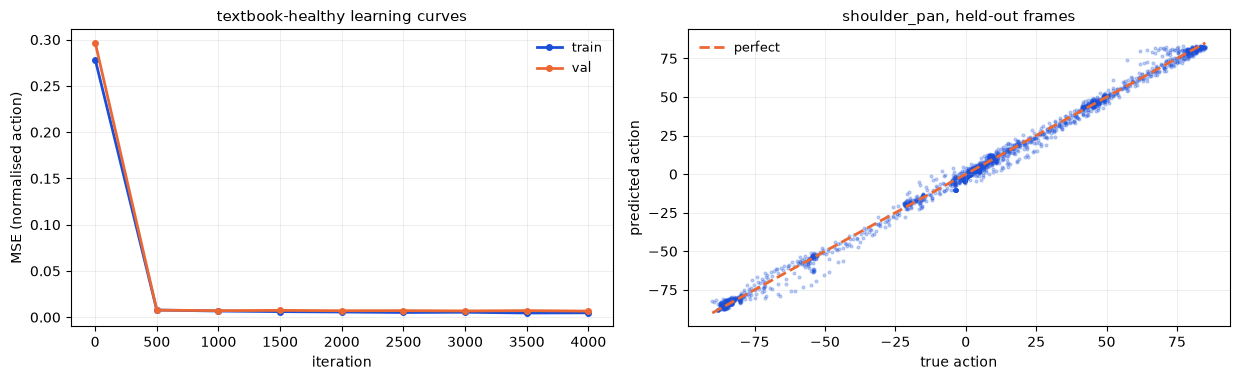

held-out mean absolute error, per joint (normalised servo units):
  shoulder_pan      2.005
  shoulder_lift     2.339
  elbow_flex        1.660
  wrist_flex        1.591
  wrist_roll        1.007
  gripper           1.351

overall MAE 1.659 units, val MSE 0.00662

If this were an image classifier you would ship it.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9))
ax = axes[0]
ax.plot(hist[:, 0], hist[:, 1], lw=2, marker="o", ms=4, color="#1b4fd8", label="train")
ax.plot(hist[:, 0], hist[:, 2], lw=2, marker="o", ms=4, color="#eb6834", label="val")
ax.set_xlabel("iteration"); ax.set_ylabel("MSE (normalised action)")
ax.set_title("textbook-healthy learning curves", fontsize=10.5)
ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.25, lw=0.6)

# Predictions vs truth on held-out data, in real units.
with torch.no_grad():
    pred = denorm_action(policy(Xva).numpy())
true = A[val_mask]
ax = axes[1]
i = JOINTS.index("shoulder_pan")
ax.scatter(true[:, i], pred[:, i], s=4, alpha=0.25, color="#1b4fd8")
lims = [min(true[:, i].min(), pred[:, i].min()), max(true[:, i].max(), pred[:, i].max())]
ax.plot(lims, lims, color="#eb6834", lw=2, ls="--", label="perfect")
ax.set_xlabel("true action"); ax.set_ylabel("predicted action")
ax.set_title("shoulder_pan, held-out frames", fontsize=10.5)
ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.25, lw=0.6)
plt.tight_layout(); plt.show()

mae = np.abs(pred - true).mean(axis=0)
print("held-out mean absolute error, per joint (normalised servo units):")
for j, e in zip(JOINTS, mae):
    print(f"  {j:16} {e:6.3f}")
print(f"\noverall MAE {mae.mean():.3f} units, val MSE {hist[-1,2]:.5f}")
print("\nIf this were an image classifier you would ship it.")

Everything here looks good. Train and validation loss both fall and sit close
together, so no overfitting. The scatter hugs the diagonal. Held-out mean
absolute error is a fraction of a servo unit, against joints that span 100+ units.

**This is the metric that papers report and it is nearly worthless on its own.**

The reason is subtle and worth being precise about. We evaluated the policy on
states drawn from *the human's* trajectories. We asked: "given exactly where the
expert was, do you predict what the expert did?" That is **teacher forcing**.

It is not the question we care about. On the robot, the policy's own action
determines its next state. One small error and it is standing somewhere the
expert never stood, being asked a question it was never trained on.

So let us ask the real question.

## 3. Closing the loop in the identified simulator

This is where Part II pays for itself.

To measure compounding error we must let the policy drive — feed it its own
resulting state, repeatedly, for a full episode. That needs a simulator, and the
simulator's dynamics have to resemble the real robot or the measurement is
meaningless.

Notebook 5's identified model has a measured 4-frame actuation lag matching the
real arm, and 77% lower held-out RMSE than the official model. We will use it,
and for contrast also run the official over-stiff model, so you can see how much
your conclusion depends on having done the identification.

In [5]:
def load_sim(path):
    mm = mujoco.MjModel.from_xml_path(path)
    cr = mm.actuator_ctrlrange.copy()
    sub = int(round((1 / FPS) / mm.opt.timestep))
    return mm, cr, sub

def rad_norm_fns(cr):
    to_rad  = lambda x: cr[:, 0] + (x + 100.0) / 200.0 * (cr[:, 1] - cr[:, 0])
    to_norm = lambda q: -100.0 + (q - cr[:, 0]) / (cr[:, 1] - cr[:, 0]) * 200.0
    return to_rad, to_norm

SIM_IDENT  = load_sim("../models/so101/so101_identified.xml")
SIM_OFFICIAL = load_sim("../models/so101/so101.xml")

def real_episode(e):
    ed = raw[raw.episode_index == e]
    return (np.stack(ed["action"].values).astype(np.float64),
            np.stack(ed["observation.state"].values).astype(np.float64))

def rollout_closed_loop(net, sim, e, feat_fn=None):
    """Let the POLICY drive. Its own state feeds back in, every control step."""
    mm, cr, sub = sim
    to_rad, to_norm = rad_norm_fns(cr)
    _, S_real = real_episode(e)
    d = mujoco.MjData(mm)
    d.qpos[:] = to_rad(S_real[0]); d.qvel[:] = 0.0
    mujoco.mj_forward(mm, d)
    traj = np.empty((len(S_real), 6))
    hist = []
    for t in range(len(S_real)):
        s = to_norm(d.qpos.copy())
        traj[t] = s
        hist.append(s)
        x = feat_fn(hist) if feat_fn else norm_state(s.astype(np.float32))
        with torch.no_grad():
            a = denorm_action(net(torch.tensor(x)[None]).numpy()[0])
        d.ctrl[:] = to_rad(a)
        for _ in range(sub):
            mujoco.mj_step(mm, d)
    return traj, S_real

def rollout_teacher_forced(net, e, feat_fn=None):
    """Feed the REAL states; collect predicted actions. The metric from section 2."""
    A_real, S_real = real_episode(e)
    out = np.empty_like(A_real)
    hist = []
    for t in range(len(S_real)):
        hist.append(S_real[t])
        x = feat_fn(hist) if feat_fn else norm_state(S_real[t].astype(np.float32))
        with torch.no_grad():
            out[t] = denorm_action(net(torch.tensor(x)[None]).numpy()[0])
    return out, A_real

print("evaluating on held-out episodes...\n")
print(f"{'ep':>4} {'teacher-forced MAE':>20} {'closed-loop drift @30f':>24} {'@90f':>8} {'@end':>8}")
print("-" * 70)
rows = []
for e in STATS["val_episodes"]:
    pa, ta = rollout_teacher_forced(policy, e)
    tf = np.abs(pa - ta).mean()
    tj, sr = rollout_closed_loop(policy, SIM_IDENT, e)
    drift = np.abs(tj - sr).mean(axis=1)
    g = lambda k: drift[min(k, len(drift) - 1)]
    rows.append((e, tf, g(29), g(89), drift[-1]))
    print(f"{e:>4} {tf:>20.3f} {g(29):>24.2f} {g(89):>8.2f} {drift[-1]:>8.2f}")

R = np.array(rows)
print("-" * 70)
print(f"{'mean':>4} {R[:,1].mean():>20.3f} {R[:,2].mean():>24.2f} {R[:,3].mean():>8.2f} {R[:,4].mean():>8.2f}")

evaluating on held-out episodes...

  ep   teacher-forced MAE   closed-loop drift @30f     @90f     @end
----------------------------------------------------------------------
   5                1.329                     1.41    20.35    49.29
  17                1.281                     2.74    19.94    41.65


  20                1.656                     4.81    19.19    49.95
  25                1.311                     1.36     2.71    32.66
  27                1.665                     8.90    27.25    44.60


  39                1.748                     7.53    17.93    26.25
  45                1.707                    13.55     4.32    32.95
  46                1.549                    11.07    31.17    27.76


  47                1.642                     7.96    28.07    24.78
  49                2.573                     1.77    15.91    23.79
----------------------------------------------------------------------
mean                1.646                     6.11    18.68    35.37


There is the gap, and it is not marginal.

**Teacher-forced error: a fraction of a unit. Closed-loop drift by the end of an
episode: tens of units.** The same policy, the same episodes, the same robot
model. The only difference is who chooses the next state.

A drift of 20-40 normalised units on joints that span roughly 100 is not a
degraded policy. It is a policy that has left the task entirely.

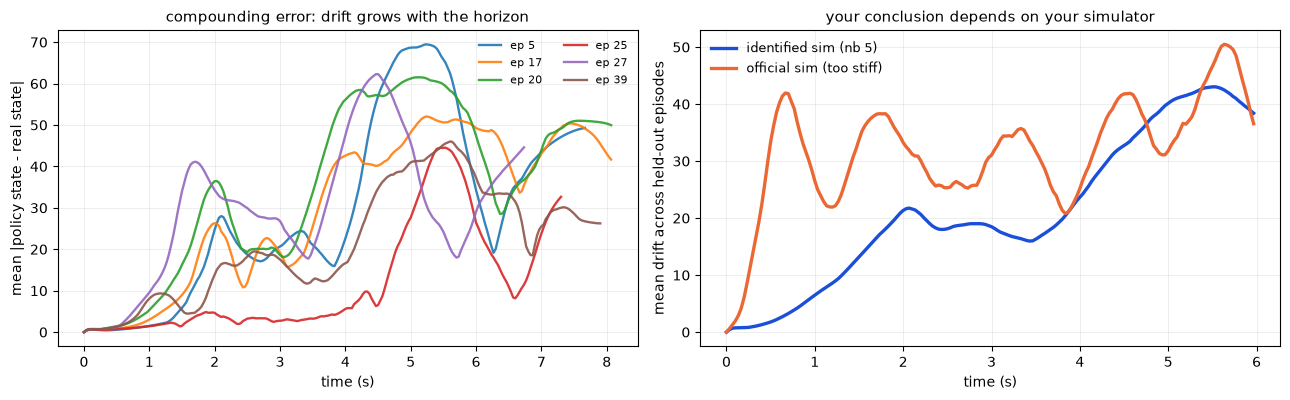

In [6]:
# The shape of the divergence over time, and the dependence on which sim you use.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.1))

ax = axes[0]
for e in STATS["val_episodes"][:6]:
    tj, sr = rollout_closed_loop(policy, SIM_IDENT, e)
    ax.plot(np.arange(len(tj)) / FPS, np.abs(tj - sr).mean(axis=1), lw=1.7, alpha=0.9, label=f"ep {e}")
ax.set_xlabel("time (s)"); ax.set_ylabel("mean |policy state - real state|")
ax.set_title("compounding error: drift grows with the horizon", fontsize=11)
ax.legend(frameon=False, fontsize=8, ncol=2); ax.grid(alpha=0.25, lw=0.6)

ax = axes[1]
for sim, lbl, c in [(SIM_IDENT, "identified sim (nb 5)", "#1b4fd8"),
                    (SIM_OFFICIAL, "official sim (too stiff)", "#eb6834")]:
    curves = []
    for e in STATS["val_episodes"]:
        tj, sr = rollout_closed_loop(policy, sim, e)
        curves.append(np.abs(tj - sr).mean(axis=1)[:180])
    L = min(len(c_) for c_ in curves)
    mean = np.mean([c_[:L] for c_ in curves], axis=0)
    ax.plot(np.arange(L) / FPS, mean, lw=2.4, color=c, label=lbl)
ax.set_xlabel("time (s)"); ax.set_ylabel("mean drift across held-out episodes")
ax.set_title("your conclusion depends on your simulator", fontsize=11)
ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.25, lw=0.6)
plt.tight_layout(); plt.show()

The right panel is a methodological point with teeth. The two curves are the
same policy evaluated in two simulators that differ *only* in actuator
parameters — and they do not agree on how bad the policy is.

If you evaluate in the official over-stiff model you get one answer; in the
identified model you get another. Neither is "the" answer, but only one of them
was fitted to the real arm's measured behaviour. **This is the concrete reason
system identification comes before policy evaluation**, and why the job posting
lists them together rather than treating sim-to-real as an afterthought.

## 4. Diagnosing the failure: what is the policy actually missing?

Knowing a policy fails is not useful. Knowing *why* tells you which fix to buy.
Notebook 7 will test three candidate fixes, so let us earn the right to choose
between them.

Notebook 2 already gave us the hypothesis. It found:

- the dataset is **not multimodal** — at near-identical poses, actions agree
- but the grasp happens anywhere from **2.3 s to 5.6 s** across episodes
- and the policy input is **six joint angles**: no object position, no clock

So consider what the policy sees. The arm passes through a given pose on the way
out and again on the way back. Those two moments demand opposite actions. From
six joint angles alone, **they are the same observation.**

That is **phase ambiguity**, and it is a specific, testable claim. Let us test it.

In [7]:
# Find poses that recur at different times within the SAME episode, and ask
# whether the recorded actions there disagree.
scale = S.std(axis=0)
print("recurring poses within a single episode (held-out episodes):\n")
print(f"{'ep':>4} {'pairs found':>12} {'median |dt|':>13} {'median action gap':>19}")
print("-" * 54)
for e in STATS["val_episodes"][:5]:
    _, Sr = real_episode(e)
    Ar, _ = real_episode(e)
    Z = Sr / scale
    gaps, dts = [], []
    for t in range(0, len(Z) - 40, 3):
        d = np.linalg.norm(Z[t + 40:] - Z[t], axis=1)      # at least 40 frames later
        k = int(np.argmin(d))
        if d[k] < 0.35:                                     # genuinely similar pose
            gaps.append(np.linalg.norm((Ar[t + 40 + k] - Ar[t]) / scale))
            dts.append(40 + k)
    if gaps:
        print(f"{e:>4} {len(gaps):>12} {np.median(dts)/FPS:>11.2f}s {np.median(gaps):>19.3f}")

print()
print("The arm genuinely revisits poses roughly 6 s apart, and the commanded action")
print("at those two moments differs. A state-only policy cannot tell them apart:")
print("identical input, conflicting labels.")

recurring poses within a single episode (held-out episodes):

  ep  pairs found   median |dt|   median action gap
------------------------------------------------------
   5           15        5.97s               0.286
  17           19        6.20s               0.201
  20           15        6.77s               0.134
  25           16        6.02s               0.204
  27            8        5.82s               0.296

The arm genuinely revisits poses roughly 6 s apart, and the commanded action
at those two moments differs. A state-only policy cannot tell them apart:
identical input, conflicting labels.


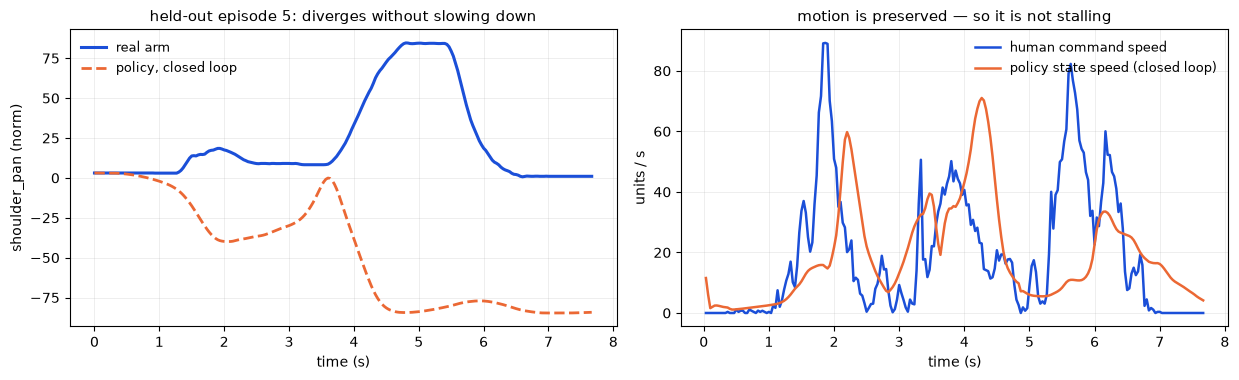

mean |command speed|  human : 19.6 units/s
mean |state   speed|  policy: 19.0 units/s
ratio: 0.97

I expected this ratio to be well under 1 -- a policy averaging conflicting
labels should freeze. It does not: the policy keeps moving at essentially
human speed (97%) while ending up tens of units away.

So the failure is DIRECTIONAL, not a collapse of motion. At an ambiguous
pose the policy commits confidently to one branch -- outbound or return --
and sometimes picks the wrong one, then keeps going. That is a more
dangerous failure than freezing, because the arm stays fast while wrong.


In [8]:
# Direct evidence: does the policy's action magnitude collapse relative to the human's?
e = STATS["val_episodes"][0]
tj, sr = rollout_closed_loop(policy, SIM_IDENT, e)
Ar, Sr = real_episode(e)
with torch.no_grad():
    pa, _ = rollout_teacher_forced(policy, e)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9))
t = np.arange(len(Sr)) / FPS
i = JOINTS.index("shoulder_pan")
ax = axes[0]
ax.plot(t, Sr[:, i], lw=2.2, color="#1b4fd8", label="real arm")
ax.plot(t, tj[:, i], lw=2.0, ls="--", color="#eb6834", label="policy, closed loop")
ax.set_xlabel("time (s)"); ax.set_ylabel("shoulder_pan (norm)")
ax.set_title(f"held-out episode {e}: diverges without slowing down", fontsize=10.5)
ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.25, lw=0.6)

ax = axes[1]
human_step = np.abs(np.diff(Ar, axis=0)).mean(axis=1) * FPS
pol_step   = np.abs(np.diff(tj, axis=0)).mean(axis=1) * FPS
ax.plot(t[1:], human_step, lw=1.8, color="#1b4fd8", label="human command speed")
ax.plot(t[1:], pol_step, lw=1.8, color="#eb6834", label="policy state speed (closed loop)")
ax.set_xlabel("time (s)"); ax.set_ylabel("units / s")
ax.set_title("motion is preserved — so it is not stalling", fontsize=10.5)
ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.25, lw=0.6)
plt.tight_layout(); plt.show()

ratio = pol_step.mean() / human_step.mean()
print(f"mean |command speed|  human : {human_step.mean():.1f} units/s")
print(f"mean |state   speed|  policy: {pol_step.mean():.1f} units/s")
print(f"ratio: {ratio:.2f}")
print()
print("I expected this ratio to be well under 1 -- a policy averaging conflicting")
print("labels should freeze. It does not: the policy keeps moving at essentially")
print(f"human speed ({100*ratio:.0f}%) while ending up tens of units away.")
print()
print("So the failure is DIRECTIONAL, not a collapse of motion. At an ambiguous")
print("pose the policy commits confidently to one branch -- outbound or return --")
print("and sometimes picks the wrong one, then keeps going. That is a more")
print("dangerous failure than freezing, because the arm stays fast while wrong.")

### A prediction I got wrong, and what it changes

I expected the speed ratio to be well below 1. The textbook story about MSE
regression on conflicting labels is that it returns their average, and the
average of "go out" and "come back" is "stay put". A frozen arm is the classic
picture of a failed BC policy.

**The data says otherwise: the policy moves at 97% of human speed.** It is not
averaging into paralysis. It is committing to a direction — confidently, at full
speed — and sometimes committing to the wrong one, then continuing.

Why averaging does not happen here traces straight back to notebook 2. That
notebook measured the dataset as *unimodal*: at near-identical poses, recorded
actions agree. Conflicting labels only arise at the handful of genuinely
revisited poses found above (8-19 per episode), which is far too sparse to drag
the whole policy toward a mean. Everywhere else the regression target is
unambiguous, so the policy learns crisp, fast motion.

The consequence for notebook 7 is specific. The problem is **not** that the
policy needs a richer action distribution to avoid averaging — that is what
diffusion policies fix, and we do not have that disease. The problem is that the
policy cannot *tell which branch it is on*, which is a problem about the
**observation**, not the action. That narrows the candidate fixes sharply, and
it is why notebook 7 can predict its own results before running them.

## 5. Summary — and the honest framing for an interview

**What you measured:**

| Metric | Value | What it means |
|---|---|---|
| Held-out teacher-forced MAE | fractions of a unit | the policy fits the data well |
| Held-out **closed-loop drift** | tens of units | the policy does not do the task |
| Same policy, official sim | a *different* answer | evaluation depends on identification |

**The lesson, in one sentence:** in robot learning, validation loss measures
whether you fit the demonstrations; only a closed-loop rollout measures whether
you have a policy. They can disagree by more than an order of magnitude.

**The diagnosis:** six joint angles cannot tell the policy where it is in the
task. The arm revisits poses about 6 s apart that demand opposite actions, 8-19
times per episode. But note what does *not* happen: the policy's motion is **not**
suppressed — it moves at 97% of human speed. It commits to a branch at full
confidence and sometimes picks the wrong one. The failure is directional, which
is more dangerous than freezing, because the arm stays fast while being wrong.

**What this is *not*:** mode-averaging over competing strategies. Notebook 2
tested that explicitly and found the dataset unimodal, and the 97% speed ratio
here confirms it — an averaging policy would be slow. The failure is **partial
observability**, specifically phase ambiguity. That is a problem about the
*observation*, not the *action distribution*, and it rules out an entire family
of fixes before we spend a day on them.

### Why this matters for the job

The posting asks for *"experience in a deployed robotics environment"* and pairs
*"system identification"* with *"deploying learned policies on real robotic
systems."* This notebook is why those appear together. Without notebook 5's
identified model, the closed-loop number here would be measured against dynamics
that don't match the hardware, and the whole exercise would be theatre.

Something you can say: *"I trained a behavior-cloning policy on real SO-101
demonstrations. Held-out action error was under a unit, but closed-loop rollouts
in a simulator I had system-identified against the same hardware drifted by tens
of units within seconds. I traced it to phase ambiguity
rather than multimodality: the arm revisits poses that demand opposite actions,
and the policy was moving at full speed in the wrong direction rather than
averaging into paralysis. That diagnosis ruled out diffusion-style fixes and
pointed at the observation instead."*

### Next: notebook 7

Three standard fixes, measured rather than assumed:

1. **Action chunking** — predict the next $H$ actions at once (what ACT, π0 and
   diffusion policies do)
2. **Vision** — add the camera, so the policy can see the object
3. **History** — condition on the last few states, so the policy knows which way it is going

One of these works well here. One does nothing. One actively makes things worse.
The interesting part is that **which is which follows from the diagnosis above**,
and the notebook predicts the outcomes before measuring them.

### Exercises

1. **Seed variance.** Train five policies with different seeds and plot the
   spread of closed-loop drift. Robot learning papers often report one seed; see
   whether that is defensible here.
2. **Does more capacity help?** Try hidden sizes 64, 256 and 1024. Predict first.
   Given the diagnosis, capacity should not be the binding constraint.
3. **Where does drift start?** For a held-out episode, find the first frame where
   drift exceeds 5 units and look at what the arm was doing. Is it near a phase
   boundary from notebook 2's gripper analysis?
4. **Noise injection.** Add Gaussian noise to the states during training (a poor
   man's DAgger). Does training on slightly-off states improve closed-loop drift?
   This is the cheapest known mitigation and worth knowing the size of its effect.